# 08.4 · Solutions

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/cloudops-one/training-ai-ml/blob/main/modules/08-deep-learning/04-backpropagation-by-hand/solutions.ipynb)

In [1]:
# --- data helper: works locally and on Colab -------------------------------
from pathlib import Path
import urllib.request

def data_path(name):
    """Return a local path to data/<name>, downloading from GitHub on Colab."""
    for parent in [Path.cwd(), *Path.cwd().parents]:
        candidate = parent / "data" / name
        if candidate.exists():
            return candidate
    url = f"https://raw.githubusercontent.com/cloudops-one/training-ai-ml/main/data/{name}"
    dest = Path(name)
    if not dest.exists():
        urllib.request.urlretrieve(url, dest)
    return dest

import os
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "2"        # hide TensorFlow start-up messages
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import warnings; warnings.filterwarnings("ignore")

def sigmoid(z): return 1 / (1 + np.exp(-z))

x = np.array([1.0, 0.5])            # one customer, two scaled features
y = 1.0                             # they churned
W = np.array([[0.2, 0.6],           # W[i, j]: input i → hidden neuron j
              [-0.4, 0.1]])
b = np.array([0.0, 0.0])            # hidden biases
v = np.array([0.5, -0.3])           # hidden → output weights
c = 0.0                             # output bias
lr = 0.5

def forward(x, W, b, v, c):
    h = sigmoid(x @ W + b)
    y_hat = sigmoid(h @ v + c)
    return h, y_hat

def backward(x, y, W, b, v, c):
    """Gradients of the log loss for one example, exactly as in the README table."""
    h, y_hat = forward(x, W, b, v, c)
    d_out = y_hat - y                       # dL/dz_out
    dv, dc = d_out * h, d_out               # output weights and bias
    dh = d_out * v                          # dL/dh_j
    d_hidden = dh * h * (1 - h)             # dL/dz_j
    dW = np.outer(x, d_hidden)              # dW[i, j] = x_i * delta_j
    return dW, d_hidden, dv, dc

def log_loss(y, y_hat):
    return -(y * np.log(y_hat) + (1 - y) * np.log(1 - y_hat))

X_xor = np.array([[0, 0], [0, 1], [1, 0], [1, 1]], dtype=float)
y_xor = np.array([0, 1, 1, 0], dtype=float)

def train_xor(seed, steps=1000, lr=2.0, hidden=2):
    """Full-batch gradient descent on the 4 XOR cases, averaging gradients over them."""
    rng = np.random.default_rng(seed)
    W, b = rng.normal(0, 1, (2, hidden)), np.zeros(hidden)
    v, c = rng.normal(0, 1, hidden), 0.0
    losses = []
    for _ in range(steps):
        grads = [backward(xi, yi, W, b, v, c) for xi, yi in zip(X_xor, y_xor)]
        W = W - lr * np.mean([g[0] for g in grads], axis=0); b = b - lr * np.mean([g[1] for g in grads], axis=0)
        v = v - lr * np.mean([g[2] for g in grads], axis=0); c = c - lr * np.mean([g[3] for g in grads])
        losses.append(np.mean([log_loss(yi, forward(xi, W, b, v, c)[1]) for xi, yi in zip(X_xor, y_xor)]))
    return (W, b, v, c), losses

## Exercise 1

In [2]:
W1 = np.array([[0.2304, 0.5835], [-0.3848, 0.0918]]); b1 = np.array([0.0304, -0.0165])
v1 = np.array([0.6217, -0.1401]); c1 = 0.2434
h1 = sigmoid(x @ W1 + b1)
y1 = sigmoid(h1 @ v1 + c1)
print("h:", h1.round(4), f" y_hat: {y1:.4f}  loss: {-np.log(y1):.3f}")

h: [0.5171 0.6486]  y_hat: 0.6163  loss: 0.484


By hand: $z_1 = 0.2304 - 0.1924 + 0.0304 = 0.0684$, $h_1 = 0.5171$; $z_2 = 0.5835 + 0.0459 - 0.0165 = 0.6129$, $h_2 = 0.6486$; $z_{\text{out}} = 0.6217(0.5171) - 0.1401(0.6486) + 0.2434 = 0.4740$; $\hat y = \sigma(0.474) = 0.6163$.

## Exercise 2

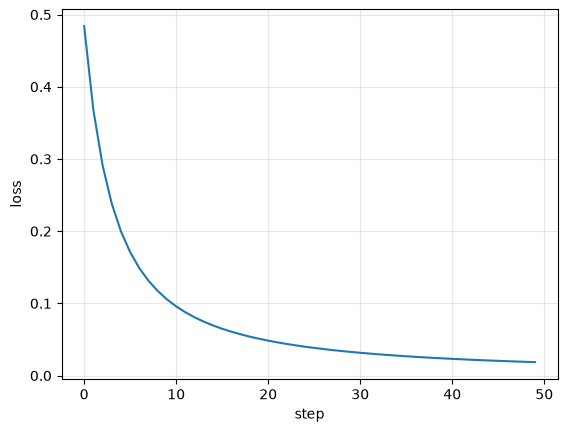

loss after 1 step 0.484, after 50 steps 0.019


In [3]:
Wk, bk, vk, ck = W.copy(), b.copy(), v.copy(), c
history = []
for step in range(50):
    dW_, db_, dv_, dc_ = backward(x, y, Wk, bk, vk, ck)
    Wk, bk, vk, ck = Wk - lr * dW_, bk - lr * db_, vk - lr * dv_, ck - lr * dc_
    history.append(log_loss(y, forward(x, Wk, bk, vk, ck)[1]))
plt.plot(history); plt.xlabel("step"); plt.ylabel("loss"); plt.grid(alpha=.3); plt.show()
print(f"loss after 1 step {history[0]:.3f}, after 50 steps {history[-1]:.3f}")

It keeps falling towards zero: with one customer, the network can always become more confident. That is memorising, not learning, which is why real training uses many examples (and lesson 08.6 watches a validation set).

## Exercise 3

In [4]:
dW0, db0, dv0, dc0 = backward(x, 0.0, W, b, v, c)
print("y = 1: dv =", backward(x, 1.0, W, b, v, c)[2].round(4), "  y = 0: dv =", dv0.round(4))
print("y = 0: dW =\n", dW0.round(4))

y = 1: dv = [-0.2434 -0.3198]   y = 0: dv = [0.2566 0.3372]
y = 0: dW =
 [[ 0.0642 -0.0347]
 [ 0.0321 -0.0173]]


With $y = 0$, $\delta_{\text{out}} = 0.5132 - 0 = +0.5132$ instead of −0.4868. **Every** gradient changes sign (and size slightly), so every weight moves the other way: the output weights shrink to pull the prediction down, and hidden neuron 2 (which pulls the output down) gets *more* active.

## Exercise 4

In [5]:
for label, kwargs in [("seed 5, default", {}), ("(a) 5,000 steps", {"steps": 5000}),
                      ("(b) lr = 5.0", {"lr": 5.0}), ("(c) 4 hidden neurons", {"hidden": 4})]:
    p, l = train_xor(seed=5, **kwargs)
    print(f"{label:22s} predictions {np.round([forward(xi, *p)[1] for xi in X_xor], 2)}  loss {l[-1]:.3f}")

seed 5, default        predictions [0.34 0.99 0.33 0.34]  loss 0.483


(a) 5,000 steps        predictions [0. 1. 1. 0.]  loss 0.001


(b) lr = 5.0           predictions [0.   1.   0.99 0.  ]  loss 0.005
(c) 4 hidden neurons   predictions [0.   1.   1.   0.01]  loss 0.004


All three fix it. Seed 5 was on a plateau, not in a dead end: more steps let it crawl across, a larger learning rate takes bigger strides over the flat part, and a wider hidden layer changes the landscape so there are more routes downhill. Wider-than-necessary networks and momentum-based optimisers (lesson 08.6) are the everyday version of these fixes.